# Monitor de incendios · Perú, octubre 2026
## ¿Qué incendios pueden crecer esta semana?

Desde inicios de octubre el Perú vive su temporada de incendios más intensa en más de una
década. Los focos de calor dicen **dónde arde hoy**. Esta tarea pregunta otra cosa:
**dónde puede arder más en los próximos días**.

Un incendio crece cuando el aire está seco, sopla viento y no llueve. Open-Meteo pronostica
esas tres cosas. Pero en vez de inventar umbrales, los **calibramos con la semana que acaba
de pasar**: ¿con qué clima ardió más cada distrito? Si el pronóstico repite ese clima, el
incendio puede crecer.

| Paso | Qué hacemos | Datos |
|---|---|---|
| 1 | Bajar los focos de calor de la última semana | NASA FIRMS, VIIRS (3 satélites) |
| 2 | Limpiar falsas alarmas con un raster | ESA WorldCover 2021 |
| 3 | Agrupar focos en incendios y elegir los 5 distritos más afectados | Límites INEI (peru-geojson) |
| 4 | Ver la semana en movimiento | — |
| 5 | Calibrar: ¿con qué clima ardió más? | Open-Meteo |
| 6 | Pronóstico: ¿qué incendios pueden crecer? | Open-Meteo |
| 7 | Medir cuánto se quemó en un incendio | Sentinel-2 L2A (dNBR) |

> Reto F · Ciencia de Datos con Python · 21 de octubre de 2026. Herramienta independiente:
> no reemplaza los reportes del COEN, INDECI, SERFOR ni SERNANP.

## 0 · Preparación

Corre con el `.venv` del curso (`uv sync --group raster --group geo`), kernel
*Python (ds-python-up)*. Ninguna fuente pide clave ni pago.

Los focos y el pronóstico cambian todos los días, así que la primera ejecución los guarda en
`data/`. Así el análisis se puede reproducir tal cual. **Para actualizar el monitor, borra
`data/focos_viirs_peru_7d.csv` y `data/open_meteo_top5.json`.**

In [1]:
import json
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import planetary_computer
import pystac_client
import rasterio
import requests

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.1f}")
pd.set_option("display.width", 160)

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

DATA = Path("data")
SALIDAS = Path("outputs")
DATA.mkdir(exist_ok=True)
SALIDAS.mkdir(exist_ok=True)

LIMA = "America/Lima"
UTM = 32718      # UTM 18S, en metros: para distancias y áreas

# Planetary Computer: catálogo STAC de rasters públicos. La firma da lectura gratis, sin clave.
CATALOGO = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

DIAS = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]

def etiqueta(dia):
    # El locale de Windows da los días en inglés: los ponemos a mano.
    return f"{DIAS[dia.weekday()]} {dia.day}"

## 1 · Focos de calor: dónde ardió esta semana

NASA FIRMS publica cada detección del sensor VIIRS: un píxel de **375 m** más caliente que
su entorno. Hay tres satélites con VIIRS (S-NPP, NOAA-20 y NOAA-21) que pasan sobre el Perú
cerca de la 1:30 y de las 13:30, así que hay hasta seis miradas al día.

El archivo «South America 7d» cubre siempre los **últimos 7 días**, así que mañana será
distinto. Por eso guardamos solo los focos del Perú en `data/`.

In [2]:
FIRMS = "https://firms.modaps.eosdis.nasa.gov/data/active_fire"
SATELITES = {
    "S-NPP": "suomi-npp-viirs-c2/csv/SUOMI_VIIRS_C2_South_America_7d.csv",
    "NOAA-20": "noaa-20-viirs-c2/csv/J1_VIIRS_C2_South_America_7d.csv",
    "NOAA-21": "noaa-21-viirs-c2/csv/J2_VIIRS_C2_South_America_7d.csv",
}
PERU_BBOX = (-81.4, -18.4, -68.6, 0.0)      # oeste, sur, este, norte
FOCOS_CSV = DATA / "focos_viirs_peru_7d.csv"

if not FOCOS_CSV.exists():
    oeste, sur, este, norte = PERU_BBOX
    partes = []
    for nombre, ruta in SATELITES.items():
        sudamerica = pd.read_csv(f"{FIRMS}/{ruta}")         # ~5 MB por satélite
        en_rectangulo = (sudamerica.longitude.between(oeste, este)
                         & sudamerica.latitude.between(sur, norte))
        partes.append(sudamerica[en_rectangulo].assign(satelite=nombre))
    pd.concat(partes).to_csv(FOCOS_CSV, index=False)

crudo = pd.read_csv(FOCOS_CSV)
print(f"{len(crudo):,} focos en el rectángulo que contiene al Perú")
print(crudo[["latitude", "longitude", "acq_date", "acq_time", "satelite", "confidence", "frp"]]
      .head(3).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

13,412 focos en el rectángulo que contiene al Perú
 latitude  longitude   acq_date  acq_time satelite confidence    frp
  -0.0740   -77.6569 2026-10-14       650    S-NPP    nominal 1.2900
  -0.0773   -77.6575 2026-10-14       650    S-NPP    nominal 1.2900
  -0.0806   -77.6580 2026-10-14       650    S-NPP    nominal 1.3400


`frp` es la *potencia radiativa del fuego*, en megavatios: cuánta energía libera el foco.
El rectángulo incluye pedazos de Ecuador, Colombia, Brasil, Bolivia y Chile, así que
cruzamos con los límites distritales del INEI. Es la misma operación punto-en-polígono de
la clase, con el mismo chequeo de CRS.

In [3]:
LIMITES_URL = ("https://raw.githubusercontent.com/juaneladio/peru-geojson/"
               "master/peru_distrital_simple.geojson")
LIMITES = DATA / "peru_distrital_simple.geojson"
if not LIMITES.exists():
    LIMITES.write_bytes(requests.get(LIMITES_URL, timeout=120).content)

distritos = gpd.read_file(LIMITES)[["IDDIST", "NOMBDIST", "NOMBPROV", "NOMBDEP", "geometry"]]
focos = gpd.GeoDataFrame(crudo, crs=4326,
                         geometry=gpd.points_from_xy(crudo.longitude, crudo.latitude))

assert focos.crs == distritos.crs, "CRS distintos: reproyectar antes de cruzar"
focos = (gpd.sjoin(focos, distritos, predicate="within")
         .drop(columns="index_right")
         .reset_index(drop=True))

# FIRMS da la hora en UTC como texto "HHMM": la pasamos a hora de Lima
hora = focos.acq_time.astype(str).str.zfill(4)
focos["fecha"] = (pd.to_datetime(focos.acq_date + " " + hora, format="%Y-%m-%d %H%M", utc=True)
                  .dt.tz_convert(LIMA))
focos["dia"] = focos.fecha.dt.tz_localize(None).dt.normalize()
CORTE = focos.fecha.max()
HOY = CORTE.tz_localize(None).normalize()

print(f"{len(focos):,} focos dentro del Perú, en {focos.NOMBDIST.nunique()} distritos")
print(f"del {focos.fecha.min():%d-%m %H:%M} al {CORTE:%d-%m %H:%M} (hora de Lima)")
pd.crosstab(focos.dia.dt.strftime("%d-%m"), focos.satelite, margins=True, margins_name="total")

9,949 focos dentro del Perú, en 653 distritos
del 14-10 00:14 al 21-10 14:19 (hora de Lima)


satelite,NOAA-20,NOAA-21,S-NPP,total
dia,,,,
14-10,429,710,464,1603
15-10,653,1054,763,2470
16-10,866,662,1385,2913
17-10,330,144,175,649
18-10,298,249,263,810
19-10,223,276,212,711
20-10,75,227,84,386
21-10,89,112,206,407
total,2963,3434,3552,9949


Hay un quiebre fuerte a mitad de semana: los focos se desploman después del 16 de octubre.
Volveremos a esto en la sección 5, porque el clima lo explica.

## 2 · Limpieza con un raster: un foco de calor no es un incendio

VIIRS detecta **calor**, no fuego. En el Perú hay tres fuentes típicas de falsas alarmas:

- **El desierto costero a mediodía.** La arena se calienta tanto que el sensor la confunde
  con fuego. Son focos solo de día, débiles y con confianza «baja».
- **Las fuentes fijas.** Plantas de gas, refinerías y fundiciones aparecen todos los días en
  el mismo lugar.
- **Los volcanes activos**, como el Sabancaya y el Ubinas.

La solución usa un raster: preguntarle a **ESA WorldCover** qué hay en el suelo bajo cada
foco. Si es desierto, agua, nieve o zona construida, ahí no hay vegetación que se queme.

**La resolución importa, como vimos en la clase.** WorldCover mide 10 m por píxel. Leerlo
a 10 m para 9 000 focos tomó 8 minutos. Usamos su *overview* (una versión reducida que viene
dentro del mismo archivo) a ~80 m: tarda unos 12 segundos y coincide con la lectura a 10 m
en el 94 % de los focos. Además, un píxel VIIRS mide 375 m, así que 80 m sobra.

In [4]:
COBERTURA = {10: "Bosque", 20: "Matorral", 30: "Pastizal", 40: "Cultivo", 50: "Construido",
             60: "Suelo desnudo", 70: "Nieve", 80: "Agua", 90: "Humedal", 95: "Manglar",
             100: "Musgo y liquen"}
NO_ARDE = {50, 60, 70, 80}          # construido, desierto, nieve, agua

teselas = list(CATALOGO.search(
    collections=["esa-worldcover"], bbox=PERU_BBOX,
    query={"esa_worldcover:product_version": {"eq": "2.0.0"}},      # versión 2021
).items())

def muestrear(tesela):
    # Clase de WorldCover bajo cada foco que cae en esta tesela de 3° x 3°.
    oeste, sur, este, norte = tesela.bbox
    dentro = (focos.longitude.between(oeste, este, inclusive="left")
              & focos.latitude.between(sur, norte, inclusive="left"))
    if not dentro.any():
        return None
    # OVERVIEW_LEVEL=2: la versión reducida 8 veces (~80 m) en vez de los 10 m originales
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"), \
         rasterio.open(tesela.assets["map"].href, OVERVIEW_LEVEL=2) as src:
        puntos = zip(focos.longitude[dentro], focos.latitude[dentro])
        return focos.index[dentro], [valor[0] for valor in src.sample(puntos)]

focos["cobertura"] = 0
with ThreadPoolExecutor(8) as pool:                  # 8 teselas a la vez
    for resultado in pool.map(muestrear, teselas):
        if resultado:
            focos.loc[resultado[0], "cobertura"] = resultado[1]

focos["clase"] = focos.cobertura.map(COBERTURA).fillna("sin dato")
focos["arde"] = ~focos.cobertura.isin(NO_ARDE)

print(f"{len(teselas)} teselas de WorldCover sobre el Perú")
(focos.groupby("clase")
      .agg(focos=("frp", "size"), frp_mediano=("frp", "median"),
           solo_de_dia=("daynight", lambda s: (s == "D").mean() * 100))
      .sort_values("focos", ascending=False))

38 teselas de WorldCover sobre el Perú


,focos,frp_mediano,solo_de_dia
clase,,,
Bosque,5128,6.1,84.5
Pastizal,3487,8.2,78.0
Matorral,414,9.0,76.8
Suelo desnudo,391,6.9,90.8
Agua,257,5.3,96.9
Cultivo,181,5.9,95.0
Construido,75,3.8,60.0
Humedal,16,7.0,100.0


In [5]:
descartados = focos[~focos.arde]
print(f"descartamos {len(descartados):,} focos ({len(descartados) / len(focos):.1%}) "
      "sobre suelo sin vegetación\n")
(descartados.groupby(["NOMBDIST", "NOMBDEP", "clase"])
            .agg(focos=("frp", "size"), frp_mediano=("frp", "median"),
                 dias=("dia", "nunique"),
                 confianza_baja=("confidence", lambda s: (s == "low").mean() * 100))
            .sort_values("focos", ascending=False)
            .head(8))

descartamos 723 focos (7.3%) sobre suelo sin vegetación



,,,focos,frp_mediano,dias,confianza_baja
NOMBDIST,NOMBDEP,clase,,,,
MOQUEGUA,MOQUEGUA,Suelo desnudo,134,7.4,4,53.7
LA JOYA,AREQUIPA,Suelo desnudo,103,7.7,3,58.3
PARACAS,ICA,Construido,30,4.7,8,16.7
CALLERIA,UCAYALI,Agua,29,4.5,3,89.7
PADRE MARQUEZ,LORETO,Agua,25,5.1,2,96.0
PEBAS,LORETO,Agua,21,8.2,2,61.9
MOLLENDO,AREQUIPA,Suelo desnudo,19,7.8,3,52.6
CONTAMANA,LORETO,Agua,18,5.2,5,38.9


La limpieza encuentra lo que esperábamos:

- **Desierto caliente.** Los focos de Moquegua, La Joya y Mollendo caen sobre **suelo
  desnudo**, más de la mitad son de confianza «baja» y el 91 % de los focos sobre suelo
  desnudo son de día.
- **Fuente fija.** Paracas aparece los **8 días** sobre una zona construida, el patrón de una
  planta industrial.
- **Reflejos del sol.** Los focos sobre **agua** en Loreto y Ucayali son casi todos de día y
  de confianza baja: el sol rebota en ríos y cochas.

Ninguno es un incendio forestal. Ojo con un costo: WorldCover es de 2021, y a ~80 m un foco
en la orilla de un río puede caer como «agua». Algún incendio real de ribera se puede haber
descartado.

## 3 · De focos a incendios

Un incendio grande produce decenas de focos. Seguimos la regla del monitor del profesor: dos
focos son **el mismo incendio** si están a ≤ 1 km y a ≤ 48 h uno del otro. Todo lo que
queda conectado por esa cadena forma un grupo, que en teoría de grafos se llama
*componente conexo*.

Las distancias se miden en metros, así que proyectamos a **UTM 18S (EPSG:32718)**. Es el
mismo error de la clase si no lo hacemos: en EPSG:4326, «1 km» no significa nada.

In [6]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree

def agrupar_incendios(puntos, distancia_m=1000, horas=48):
    # Une focos a <= distancia_m y <= horas: cada grupo conectado es un incendio.
    xy = np.c_[puntos.geometry.x, puntos.geometry.y]
    pares = cKDTree(xy).query_pairs(r=distancia_m, output_type="ndarray")
    t = puntos.fecha.values
    horas_entre = np.abs(t[pares[:, 0]] - t[pares[:, 1]]) / np.timedelta64(1, "h")
    pares = pares[horas_entre <= horas]
    n = len(puntos)
    grafo = coo_matrix((np.ones(len(pares)), (pares[:, 0], pares[:, 1])), shape=(n, n))
    return connected_components(grafo, directed=False)[1]

veg = focos[focos.arde].to_crs(UTM).reset_index(drop=True)
veg["incendio"] = agrupar_incendios(veg)

# Huella: cada foco es un píxel VIIRS de 375 m; la unión de los píxeles es el área afectada
pixeles = veg.copy()
pixeles["geometry"] = veg.buffer(187.5, cap_style="square")
huellas = pixeles.dissolve("incendio")

incendios = veg.groupby("incendio").agg(
    focos=("frp", "size"), frp_total=("frp", "sum"),
    inicio=("fecha", "min"), ultimo=("fecha", "max"),
    distrito=("NOMBDIST", lambda s: s.mode()[0]),
    depto=("NOMBDEP", lambda s: s.mode()[0]),
)
incendios["huella_ha"] = huellas.area / 1e4
incendios["activo"] = incendios.ultimo >= CORTE - pd.Timedelta("48h")
incendios = gpd.GeoDataFrame(incendios, geometry=huellas.geometry, crs=UTM)

print(f"{len(veg):,} focos en vegetación -> {len(incendios):,} incendios")
print(f"  con huella de 100 ha o más : {(incendios.huella_ha >= 100).sum()}")
print(f"  activos en las últimas 48 h: {incendios.activo.sum()}")

9,226 focos en vegetación -> 2,665 incendios
  con huella de 100 ha o más : 127
  activos en las últimas 48 h: 343


**Los 5 distritos más afectados.** Sumamos la huella de todos los focos de cada distrito.

Es una **cota superior**: el píxel VIIRS de 375 m es mucho más grande que la mayoría de los
fuegos. En la sección 7 medimos el área real de un incendio con Sentinel-2 y vemos cuánto
se infla la huella.

In [7]:
por_distrito = pixeles.dissolve(["IDDIST", "NOMBDIST", "NOMBDEP"])
por_distrito = (
    por_distrito.assign(huella_ha=por_distrito.area / 1e4)[["huella_ha"]]
    .join(veg.groupby(["IDDIST", "NOMBDIST", "NOMBDEP"])
             .agg(focos=("frp", "size"), incendios=("incendio", "nunique"),
                  ultimo_foco=("fecha", "max")))
    .sort_values("huella_ha", ascending=False)
    .reset_index()
)

TOP5 = por_distrito.head(5).copy()

# El incendio principal de cada distrito: el de mayor huella. Ahí pedimos el clima.
principal = (veg[veg.IDDIST.isin(TOP5.IDDIST)]
             .groupby(["IDDIST", "incendio"]).size().reset_index()
             .merge(incendios[["huella_ha"]], left_on="incendio", right_index=True)
             .sort_values("huella_ha")
             .groupby("IDDIST").tail(1)
             .set_index("IDDIST").incendio)
TOP5["incendio"] = TOP5.IDDIST.map(principal)
centros = incendios.loc[TOP5.incendio].centroid.to_crs(4326)
TOP5["lat"], TOP5["lon"] = centros.y.values, centros.x.values
TOP5["nombre"] = TOP5.NOMBDIST.str.title()

print(f"top 5 = {por_distrito.head(5).huella_ha.sum() / por_distrito.huella_ha.sum():.0%} "
      "de la huella nacional")
por_distrito.head(8)

top 5 = 17% de la huella nacional


,IDDIST,NOMBDIST,NOMBDEP,huella_ha,focos,incendios,ultimo_foco
0,250106,NUEVA REQUENA,UCAYALI,"3,864.5",474,82,2026-10-21 13:58:00-05:00
1,120608,RIO TAMBO,JUNIN,"3,691.4",468,64,2026-10-21 14:17:00-05:00
2,250104,MASISEA,UCAYALI,"3,179.3",315,80,2026-10-21 14:17:00-05:00
3,250201,RAYMONDI,UCAYALI,"2,643.0",255,110,2026-10-21 14:17:00-05:00
4,250203,TAHUANIA,UCAYALI,"2,319.1",322,53,2026-10-21 14:17:00-05:00
5,030104,CURAHUASI,APURIMAC,"2,107.5",286,8,2026-10-20 12:54:00-05:00
6,120606,PANGOA,JUNIN,"1,962.8",168,72,2026-10-21 13:56:00-05:00
7,250107,MANANTAY,UCAYALI,"1,831.1",233,17,2026-10-16 14:10:00-05:00


## 4 · La semana en movimiento

Dos vistas de lo que pasó entre el 14 y el 21 de octubre:

1. **Mapa interactivo de todo el Perú**: un cuadro por día, con el color según la potencia
   del fuego. Usa el *play* o arrastra el control de abajo. También se guarda en
   `outputs/evolucion_focos.html`, que se abre en cualquier navegador.
2. **Animación de los 5 distritos más afectados**: cómo se acumula la huella día a día.
   Queda guardada como GIF en `outputs/evolucion_top5.gif` para el README.

In [8]:
import plotly.express as px

anim = pd.DataFrame({
    "lat": veg.latitude, "lon": veg.longitude, "frp": veg.frp.round(1),
    "distrito": veg.NOMBDIST.str.title(), "depto": veg.NOMBDEP.str.title(),
    "hora": veg.fecha.dt.strftime("%H:%M"), "cobertura": veg.clase, "dia": veg.dia,
}).sort_values("dia")
anim["día"] = anim.dia.map(lambda d: f"{etiqueta(d)} de octubre")

fig = px.scatter_map(
    anim, lat="lat", lon="lon", color="frp", animation_frame="día",
    hover_name="distrito",
    hover_data={"depto": True, "hora": True, "cobertura": True, "frp": True,
                "lat": False, "lon": False, "día": False},
    color_continuous_scale="YlOrRd", range_color=(0, 40),
    zoom=4.3, center={"lat": -9.6, "lon": -74.8}, height=650,
    map_style="carto-darkmatter",
    title="Focos de calor VIIRS en vegetación, día por día · Perú, 14 al 21 de octubre de 2026",
)
for cuadro in [fig, *fig.frames]:
    cuadro.data[0].marker.size = 6
fig.update_layout(coloraxis_colorbar={"title": "FRP (MW)"},
                  margin={"l": 0, "r": 0, "t": 40, "b": 0})
fig.write_html(SALIDAS / "evolucion_focos.html", include_plotlyjs="cdn")
fig.show()

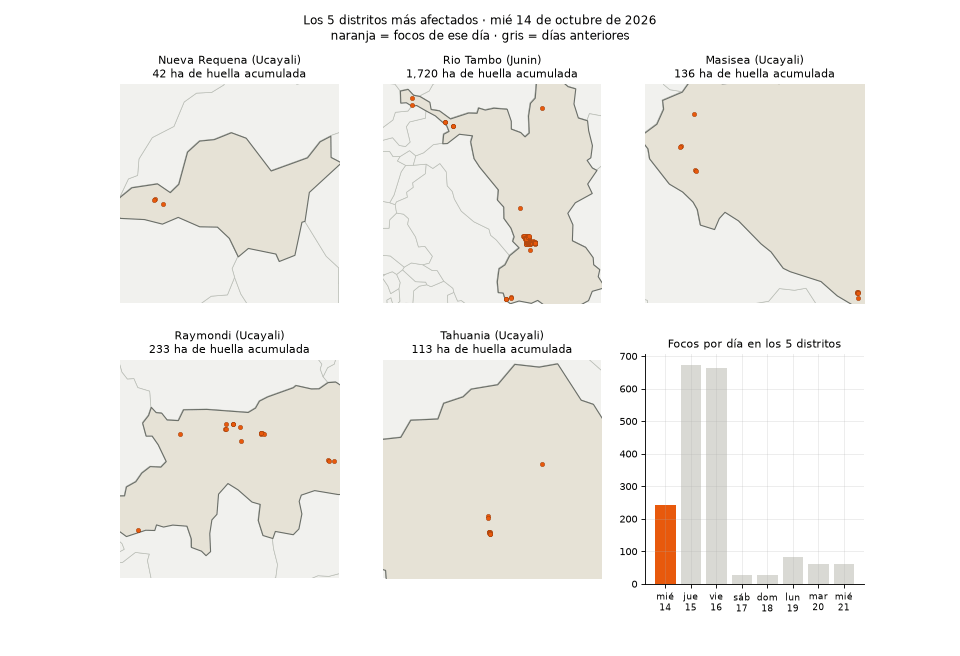

In [9]:
from IPython.display import Image, display
from matplotlib.animation import FuncAnimation, PillowWriter

dias = list(pd.DatetimeIndex(veg.dia.unique()).sort_values())
distritos_utm = distritos.to_crs(UTM)
en_top5 = veg[veg.IDDIST.isin(TOP5.IDDIST)]
focos_dia_top5 = en_top5.groupby("dia").size().reindex(dias, fill_value=0)

# Hectáreas acumuladas por distrito y día (unión de los píxeles de 375 m hasta ese día)
cuadros_top5 = pixeles[pixeles.IDDIST.isin(TOP5.IDDIST)]
acumulado = {(i, dia): cuadros_top5[(cuadros_top5.IDDIST == i) & (cuadros_top5.dia <= dia)]
                       .union_all().area / 1e4
             for i in TOP5.IDDIST for dia in dias}

# Encuadre de cada panel: la zona con focos del distrito, más 3 km de margen
encuadres = {}
for _, d in TOP5.iterrows():
    x0, y0, x1, y1 = en_top5[en_top5.IDDIST == d.IDDIST].total_bounds
    lado = max(x1 - x0, y1 - y0) / 2 + 3000
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    encuadres[d.IDDIST] = (cx - lado, cx + lado, cy - lado, cy + lado)

fig, ejes = plt.subplots(2, 3, figsize=(12, 8.2))
ejes = ejes.ravel()

def dibujar(i):
    dia = dias[i]
    for ax, (_, d) in zip(ejes, TOP5.iterrows()):
        ax.clear()
        x0, x1, y0, y1 = encuadres[d.IDDIST]
        vecinos = distritos_utm.cx[x0:x1, y0:y1]
        vecinos.plot(ax=ax, color="#f1f1ee", edgecolor="#b9bdb5", linewidth=0.6)
        vecinos[vecinos.IDDIST == d.IDDIST].plot(
            ax=ax, color="#e6e2d6", edgecolor="#6b6f68", linewidth=1)
        propio = en_top5[en_top5.IDDIST == d.IDDIST]
        antes, hoy = propio[propio.dia < dia], propio[propio.dia == dia]
        if len(antes):
            antes.plot(ax=ax, color="#5b5f66", markersize=3)
        if len(hoy):
            hoy.plot(ax=ax, color="#e8590c", markersize=16, edgecolor="#7a2a00", linewidth=0.3)
        ax.set_xlim(x0, x1)
        ax.set_ylim(y0, y1)
        ax.set_axis_off()
        ax.set_title(f"{d.nombre} ({d.NOMBDEP.title()})\n"
                     f"{acumulado[d.IDDIST, dia]:,.0f} ha de huella acumulada",
                     fontsize=9.5)
    barras = ejes[5]
    barras.clear()
    colores = ["#e8590c" if x == dia else ("#5b5f66" if x < dia else "#d9d9d4") for x in dias]
    barras.bar(range(len(dias)), focos_dia_top5.values, color=colores)
    barras.set_xticks(range(len(dias)), [etiqueta(x).replace(" ", "\n") for x in dias],
                      fontsize=8)
    barras.set_title("Focos por día en los 5 distritos", fontsize=9.5)
    fig.suptitle(f"Los 5 distritos más afectados · {etiqueta(dia)} de octubre de 2026\n"
                 "naranja = focos de ese día · gris = días anteriores",
                 fontsize=11)

animacion = FuncAnimation(fig, dibujar, frames=len(dias))
animacion.save(SALIDAS / "evolucion_top5.gif", writer=PillowWriter(fps=1), dpi=80)
dibujar(len(dias) - 1)
fig.savefig(SALIDAS / "huella_top5_final.png", dpi=110, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(SALIDAS / "evolucion_top5.gif")))

Los cinco distritos son amazónicos: cuatro de Ucayali (Coronel Portillo y Atalaya) y Río
Tambo, en la selva de Junín. No son un incendio grande cada uno, sino **decenas de fuegos
chicos dispersos**, el patrón de las quemas agrícolas y de desbosque en la selva. Casi toda
la huella se forma entre el 14 y el 16 de octubre (casi 9 de cada 10 focos); después solo
se suman retazos.

## 5 · ¿Con qué clima ardió más? Calibrar con la semana pasada

Open-Meteo da, sin clave, el clima de los últimos días y el pronóstico de los siguientes.
Lo pedimos en el **incendio principal** de cada distrito, todo en una sola llamada (varias
coordenadas separadas por comas). Estas son las variables:

| Variable | Por qué importa |
|---|---|
| Lluvia (mm) | Moja la vegetación y frena el fuego |
| Humedad relativa mínima | Aire seco = vegetación seca |
| Ráfagas y dirección del viento | Empujan el frente del fuego y dicen hacia dónde |
| **HDW** = déficit de presión de vapor × viento | Junta calor, sequedad y viento en un solo número |

El **Hot-Dry-Windy Index** (HDW; Srock et al., 2018) multiplica cuánta agua «le falta» al
aire (déficit de presión de vapor, en hPa) por la velocidad del viento (m/s). Usamos el
máximo horario de cada día. Su versión original usa los primeros 500 m de la atmósfera; aquí
usamos los datos de superficie, así que sirve para **comparar días entre sí**, no contra
umbrales publicados.

In [10]:
OPEN_METEO = "https://api.open-meteo.com/v1/forecast"
CLIMA_JSON = DATA / "open_meteo_top5.json"

if not CLIMA_JSON.exists():
    parametros = {
        "latitude": ",".join(f"{v:.4f}" for v in TOP5.lat),
        "longitude": ",".join(f"{v:.4f}" for v in TOP5.lon),
        "daily": ("precipitation_sum,precipitation_probability_max,relative_humidity_2m_min,"
                  "temperature_2m_max,wind_gusts_10m_max,wind_direction_10m_dominant"),
        "hourly": "vapour_pressure_deficit,wind_speed_10m",
        "past_days": 8, "forecast_days": 8, "timezone": LIMA,
    }
    respuesta = requests.get(OPEN_METEO, params=parametros, timeout=120)
    respuesta.raise_for_status()
    CLIMA_JSON.write_text(json.dumps(respuesta.json()))

lugares = json.loads(CLIMA_JSON.read_text())

tablas = []
for (_, d), lugar in zip(TOP5.iterrows(), lugares):
    horario = pd.DataFrame(lugar["hourly"])
    # HDW: déficit de presión de vapor (kPa -> hPa) x viento (km/h -> m/s)
    horario["hdw"] = horario.vapour_pressure_deficit * 10 * horario.wind_speed_10m / 3.6
    horario["fecha"] = pd.to_datetime(horario.time).dt.normalize()
    diario = pd.DataFrame(lugar["daily"]).assign(fecha=lambda t: pd.to_datetime(t.time))
    diario = diario.merge(horario.groupby("fecha").hdw.max().reset_index(), on="fecha")
    tablas.append(diario.assign(IDDIST=d.IDDIST, nombre=d.nombre, elevacion=lugar["elevation"]))

clima = (pd.concat(tablas, ignore_index=True)
         .rename(columns={"precipitation_sum": "lluvia_mm",
                          "precipitation_probability_max": "prob_lluvia",
                          "relative_humidity_2m_min": "hr_min",
                          "temperature_2m_max": "tmax",
                          "wind_gusts_10m_max": "rafaga_kmh",
                          "wind_direction_10m_dominant": "viento_desde"})
         .drop(columns="time"))
clima["periodo"] = np.where(clima.fecha <= HOY, "reciente", "pronóstico")

# Solo las pasadas de la tarde (~13:30): miran todos los días a la misma hora, con el fuego
# en su momento más activo. La de la 1:30 ve el fuego de la tarde ANTERIOR y lo cuenta
# en el día siguiente, que puede ser justo el día de la lluvia.
tarde = veg[veg.IDDIST.isin(TOP5.IDDIST) & (veg.daynight == "D")]
focos_dia = tarde.groupby(["IDDIST", "dia"]).size()
clima["focos"] = [focos_dia.get((i, f), 0) for i, f in zip(clima.IDDIST, clima.fecha)]

print(f"{len(lugares)} puntos · {clima.fecha.min():%d-%m} a {clima.fecha.max():%d-%m} · "
      f"pronóstico desde el {HOY + pd.Timedelta('1D'):%d-%m}")
(clima[clima.fecha.between(dias[0], HOY)]
      .assign(dia=lambda t: t.fecha.dt.strftime("%d-%m"))
      .pivot_table(index="nombre", columns="dia", values="lluvia_mm", sort=False)
      .round(0))

5 puntos · 13-10 a 28-10 · pronóstico desde el 22-10


dia,14-10,15-10,16-10,17-10,18-10,19-10,20-10,21-10
nombre,,,,,,,,
Nueva Requena,4.0,1.0,0.0,38.0,3.0,1.0,28.0,14.0
Rio Tambo,0.0,1.0,1.0,5.0,1.0,0.0,3.0,16.0
Masisea,1.0,0.0,1.0,22.0,1.0,1.0,14.0,2.0
Raymondi,3.0,2.0,8.0,8.0,3.0,1.0,3.0,7.0
Tahuania,5.0,3.0,6.0,46.0,2.0,1.0,10.0,2.0


La tabla de arriba es la **lluvia diaria (mm)** de la semana pasada. Ahora la ponemos al
lado de los focos.

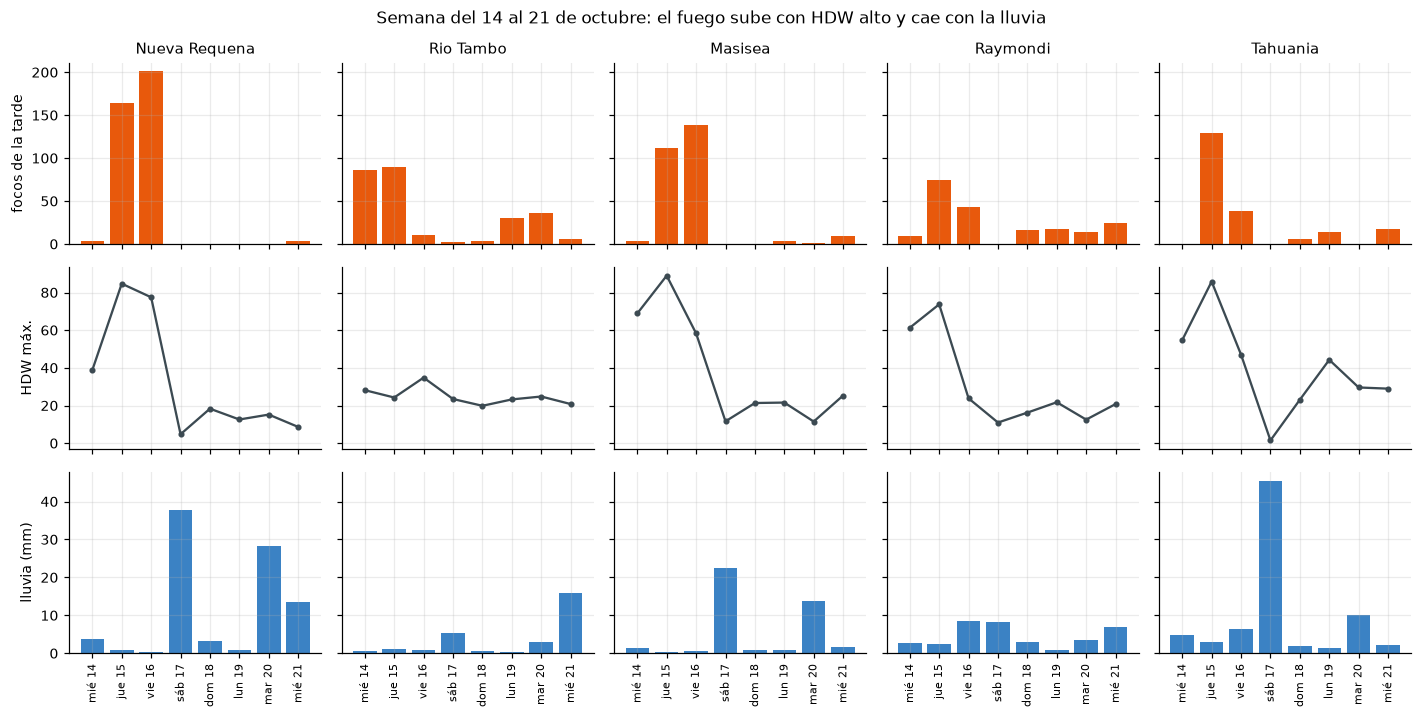

In [11]:
semana = clima[clima.fecha.between(dias[0], HOY)]
fig, ejes = plt.subplots(3, 5, figsize=(13, 6.6), sharex=True, sharey="row")

for j, (_, d) in enumerate(TOP5.iterrows()):
    t = semana[semana.IDDIST == d.IDDIST]
    x = np.arange(len(t))
    ejes[0, j].bar(x, t.focos, color="#e8590c")
    ejes[1, j].plot(x, t.hdw, color="#3c4a52", marker="o", markersize=3)
    ejes[2, j].bar(x, t.lluvia_mm, color="#3b82c4")
    ejes[0, j].set_title(d.nombre, fontsize=9.5)
    ejes[2, j].set_xticks(x, [etiqueta(f) for f in t.fecha], fontsize=7, rotation=90)

ejes[0, 0].set_ylabel("focos de la tarde")
ejes[1, 0].set_ylabel("HDW máx.")
ejes[2, 0].set_ylabel("lluvia (mm)")
fig.suptitle("Semana del 14 al 21 de octubre: el fuego sube con HDW alto y cae con la lluvia",
             fontsize=11)
plt.tight_layout()
fig.savefig(SALIDAS / "calibracion_clima.png", dpi=130, bbox_inches="tight")
plt.show()

**El 17 de octubre llovió en los cinco distritos y los focos se desplomaron.** En cuatro
de ellos, el HDW tuvo sus máximos de la semana entre el 14 y el 16 y casi no llovió: ahí ardió
casi toda la huella. Después del 17 el HDW no volvió a esos niveles, y el fuego tampoco.

**Río Tambo es la excepción.** Su HDW es bajo y casi plano toda la semana, porque es un valle
más húmedo y con menos viento. Ahí lo que pesó fue que casi no llovió hasta el 21. Por eso
calibramos **distrito por distrito** y no con un umbral único.

Hay que tener una precaución: un día de lluvia también es un día **nublado**, y VIIRS no ve a
través de las nubes. Parte de la caída del 17 puede ser que el satélite no pudo mirar. Pero
los focos siguieron bajos los cuatro días siguientes, con un HDW mucho menor que en el pico:
no fue solo un día nublado.

**Calibración.** Para cada distrito definimos sus **días pico**: los días con al menos la
mitad de los focos de la tarde de su día récord. De esos días anotamos dos cosas: el HDW
promedio y la lluvia máxima. Esas son las condiciones con las que más ardió **ese**
distrito.

No usamos «los 3 días con más focos» porque, si un distrito ardió fuerte solo dos días, el
tercero sería un día con 4 focos: no es un pico.

In [12]:
record = semana.groupby("IDDIST").focos.transform("max")
pico = semana[semana.focos >= record / 2]
umbrales = pico.groupby("IDDIST").agg(
    dias_pico=("fecha", lambda s: ", ".join(etiqueta(f) for f in sorted(s))),
    focos_pico=("focos", "sum"),
    hdw_pico=("hdw", "mean"),
    lluvia_pico=("lluvia_mm", "max"),
)
umbrales = TOP5[["IDDIST", "nombre"]].merge(umbrales.reset_index(), on="IDDIST")
umbrales

,IDDIST,nombre,dias_pico,focos_pico,hdw_pico,lluvia_pico
0,250106,Nueva Requena,"jue 15, vie 16",365,81.1,1.0
1,120608,Rio Tambo,"mié 14, jue 15",176,26.2,1.1
2,250104,Masisea,"jue 15, vie 16",251,73.6,0.6
3,250201,Raymondi,"jue 15, vie 16",117,48.8,8.4
4,250203,Tahuania,jue 15,129,85.8,3.1


## 6 · Pronóstico: ¿qué incendios pueden crecer esta semana?

La regla sale directo de la calibración. Un **día de riesgo** es un día pronosticado con:

- **HDW ≥ HDW de los días pico** del distrito (tan seco y ventoso como cuando más ardió), y
- **lluvia ≤ la lluvia de los días pico** (no llueve más que entonces).

Es decir: *el clima vuelve a parecerse al de la semana en que ese mismo distrito ardió*.
Probamos antes la «regla 30-30-30» de los manuales (más de 30 °C, humedad menor a 30 % y
viento mayor a 30 km/h), pero no sirve en la selva: en los días pico la humedad mínima
estuvo entre 38 % y 58 %, nunca bajo 30 %, y aun así ardió.

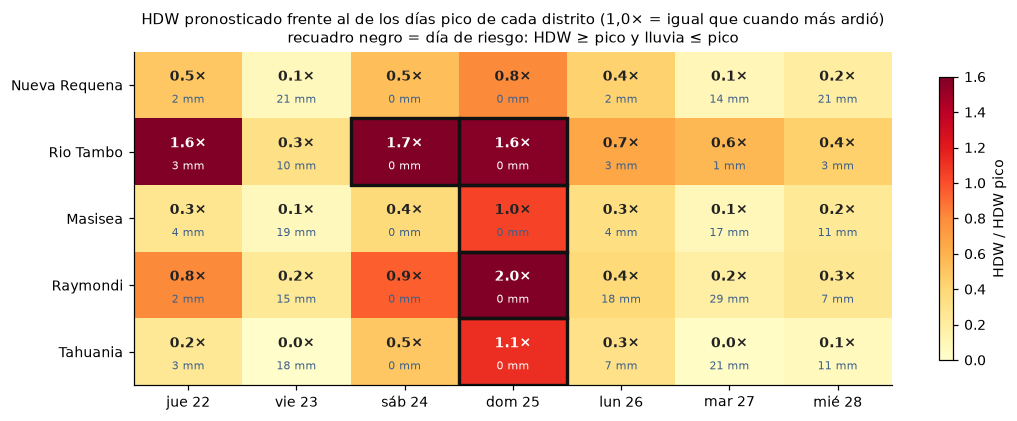

In [13]:
pron = clima[clima.periodo == "pronóstico"].merge(umbrales, on=["IDDIST", "nombre"])
pron["hdw_relativo"] = pron.hdw / pron.hdw_pico
pron["riesgo"] = (pron.hdw >= pron.hdw_pico) & (pron.lluvia_mm <= pron.lluvia_pico)

orden = TOP5.nombre.tolist()
matriz = pron.pivot(index="nombre", columns="fecha", values="hdw_relativo").loc[orden]
lluvia = pron.pivot(index="nombre", columns="fecha", values="lluvia_mm").loc[orden]
riesgo = pron.pivot(index="nombre", columns="fecha", values="riesgo").loc[orden]

fig, ax = plt.subplots(figsize=(10, 3.9))
imagen = ax.imshow(matriz.values, cmap="YlOrRd", vmin=0, vmax=1.6, aspect="auto")
for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        valor = matriz.iat[i, j]
        ax.text(j, i - 0.12, f"{valor:.1f}×", ha="center", va="center", fontsize=9,
                fontweight="bold", color="white" if valor > 1.1 else "#222")
        ax.text(j, i + 0.22, f"{lluvia.iat[i, j]:.0f} mm", ha="center", va="center",
                fontsize=7.5, color="white" if valor > 1.1 else "#3b5f8a")
        if riesgo.iat[i, j]:
            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False,
                                       edgecolor="#111", linewidth=2.2))
ax.set_xticks(range(matriz.shape[1]), [etiqueta(f) for f in matriz.columns])
ax.set_yticks(range(matriz.shape[0]), matriz.index)
ax.grid(False)
ax.set_title("HDW pronosticado frente al de los días pico de cada distrito (1,0× = igual que "
             "cuando más ardió)\nrecuadro negro = día de riesgo: HDW ≥ pico y lluvia ≤ pico",
             fontsize=9.5)
fig.colorbar(imagen, ax=ax, shrink=0.85, label="HDW / HDW pico")
plt.tight_layout()
fig.savefig(SALIDAS / "pronostico_riesgo.png", dpi=130, bbox_inches="tight")
plt.show()

In [14]:
RUMBOS = ["norte", "noreste", "este", "sureste", "sur", "suroeste", "oeste", "noroeste"]

def media_circular(grados):
    # Promedio de direcciones: 350° y 10° deben dar 0°, no 180°.
    rad = np.deg2rad(grados)
    return np.rad2deg(np.arctan2(np.sin(rad).mean(), np.cos(rad).mean())) % 360

def rumbo(grados):
    return RUMBOS[int((grados + 22.5) // 45) % 8]

filas = []
for _, d in TOP5.iterrows():
    p = pron[pron.IDDIST == d.IDDIST]
    criticos = p[p.riesgo]
    base = criticos if len(criticos) else p.nlargest(1, "hdw_relativo")
    # El dato de Open-Meteo dice DE DÓNDE viene el viento; el fuego avanza hacia el lado opuesto
    hacia = (media_circular(base.viento_desde) + 180) % 360
    filas.append({
        "distrito": d.nombre, "depto": d.NOMBDEP.title(),
        "huella_ha": d.huella_ha, "ultimo_foco": d.ultimo_foco.strftime("%d-%m %H:%M"),
        "dias_riesgo": len(criticos),
        "cuales": ", ".join(etiqueta(f) for f in criticos.fecha) or "—",
        "hdw_max_relativo": p.hdw_relativo.max(),
        "lluvia_7d_mm": p.lluvia_mm.sum(),
        "rafaga_max_kmh": p.rafaga_kmh.max(),
        "avanzaria_hacia": rumbo(hacia), "rumbo_grados": hacia,
    })

ranking = (pd.DataFrame(filas)
           .sort_values(["dias_riesgo", "hdw_max_relativo"], ascending=False)
           .reset_index(drop=True))
ranking.index = ranking.index + 1
ranking.to_csv(SALIDAS / "ranking_riesgo.csv", index_label="puesto")
ranking.drop(columns="rumbo_grados")

,distrito,depto,huella_ha,ultimo_foco,dias_riesgo,cuales,hdw_max_relativo,lluvia_7d_mm,rafaga_max_kmh,avanzaria_hacia
1,Rio Tambo,Junin,"3,691.4",21-10 14:17,2,"sáb 24, dom 25",1.7,19.0,28.4,oeste
2,Raymondi,Ucayali,"2,643.0",21-10 14:17,1,dom 25,2.0,71.8,37.4,sureste
3,Tahuania,Ucayali,"2,319.1",21-10 14:17,1,dom 25,1.1,59.6,37.8,sur
4,Masisea,Ucayali,"3,179.3",21-10 14:17,1,dom 25,1.0,54.8,36.4,sur
5,Nueva Requena,Ucayali,"3,864.5",21-10 13:58,0,—,0.8,60.1,30.6,sur


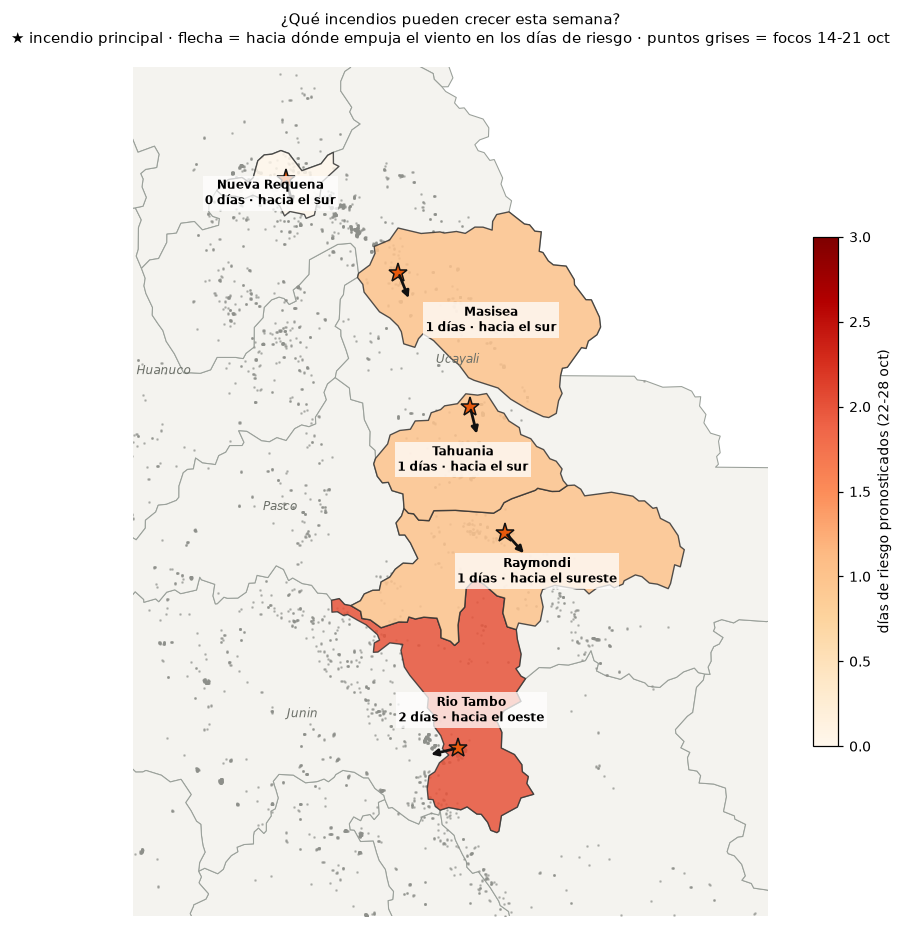

In [15]:
departamentos = distritos_utm.dissolve("NOMBDEP")
zona = TOP5.merge(distritos_utm[["IDDIST", "geometry"]], on="IDDIST")
zona = gpd.GeoDataFrame(zona, geometry="geometry", crs=UTM).merge(
    ranking[["distrito", "dias_riesgo", "avanzaria_hacia", "rumbo_grados"]],
    left_on="nombre", right_on="distrito")
x0, y0, x1, y1 = zona.total_bounds
margen = 60_000

fig, ax = plt.subplots(figsize=(8.5, 8.5))
departamentos.plot(ax=ax, color="#f4f3ef", edgecolor="#9aa09a", linewidth=0.7)
veg.plot(ax=ax, color="#8d8f8a", markersize=0.6, alpha=0.5)
zona.plot(ax=ax, column="dias_riesgo", cmap="OrRd", vmin=0, vmax=max(3, zona.dias_riesgo.max()),
          edgecolor="#333", linewidth=0.9, alpha=0.85, legend=True,
          legend_kwds={"label": "días de riesgo pronosticados (22-28 oct)", "shrink": 0.6})
for _, z in zona.iterrows():
    fuego = incendios.loc[z.incendio].geometry.centroid
    largo = 22_000
    ang = np.deg2rad(z.rumbo_grados)
    ax.annotate("", xy=(fuego.x + largo * np.sin(ang), fuego.y + largo * np.cos(ang)),
                xytext=(fuego.x, fuego.y),
                arrowprops={"arrowstyle": "-|>", "color": "#111", "lw": 1.8})
    ax.plot(fuego.x, fuego.y, marker="*", color="#e8590c", markersize=13, markeredgecolor="#111")
    p = z.geometry.representative_point()
    ax.text(p.x, p.y - 12_000, f"{z.nombre}\n{z.dias_riesgo} días · hacia el {z.avanzaria_hacia}",
            ha="center", fontsize=8, fontweight="bold",
            bbox={"facecolor": "white", "alpha": 0.75, "edgecolor": "none", "pad": 1.5})
for nombre, fila in departamentos.iterrows():
    c = fila.geometry.representative_point()
    if x0 - margen < c.x < x1 + margen and y0 - margen < c.y < y1 + margen:
        ax.text(c.x, c.y, nombre.title(), fontsize=8, color="#6b6f68", style="italic",
                ha="center")
ax.set_xlim(x0 - margen, x1 + margen)
ax.set_ylim(y0 - margen, y1 + margen)
ax.set_axis_off()
ax.set_title("¿Qué incendios pueden crecer esta semana?\n"
             "★ incendio principal · flecha = hacia dónde empuja el viento en los días de riesgo "
             "· puntos grises = focos 14-21 oct", fontsize=10)
plt.tight_layout()
fig.savefig(SALIDAS / "mapa_riesgo.png", dpi=130, bbox_inches="tight")
plt.show()

## 7 · Cuánto se quemó: dNBR en Nueva Requena

Este es el mínimo de la entrega: un incendio, su dNBR, un mapa y las hectáreas, **con fechas
y porcentaje de nubes**. Elegimos el incendio principal de **Nueva Requena**, el distrito más
afectado.

**¿Por qué no otro?** Revisamos los cinco y solo dos tienen una imagen Sentinel-2 despejada
*después* del fuego:

- Río Tambo y Raymondi: todas las imágenes posteriores tienen más de 25 % de nubes sobre
  el incendio.
- Tahuania: tiene imagen, pero con 21 % de nubes sobre el incendio.
- Nueva Requena: tiene una prácticamente sin nubes.

En la selva, **las nubes deciden qué se puede medir**.

**El método**, de a una decisión por vez:

- **NBR = (NIR − SWIR2) / (NIR + SWIR2)**, con las bandas B08 (10 m) y B12 (20 m). La
  vegetación sana refleja mucho infrarrojo cercano (NIR); lo quemado refleja más infrarrojo de
  onda corta (SWIR). Trabajamos a 20 m.
- **dNBR = NBR antes − NBR después**: cuanto más alto, más severo el daño.
- **El offset.** Desde 2022, ESA suma 1000 a cada valor de Sentinel-2. Hay que restarlo: si no,
  el NBR sale sesgado.
- **Máscara con la capa SCL**: fuera nubes, sombras, cirros y agua.
- **Sembrado con focos.** Un dNBR alto también puede ser una cosecha o un cambio de
  temporada. Por eso solo contamos las manchas con dNBR ≥ 0,10 que **tocan un foco VIIRS**
  de este incendio.

In [16]:
from rasterio.enums import Resampling
from rasterio.features import rasterize, shapes
from rasterio.plot import plotting_extent
from rasterio.windows import bounds as limites_ventana
from rasterio.windows import from_bounds
from scipy import ndimage
from shapely.geometry import box, shape

ELEGIDO = TOP5.iloc[0]                         # Nueva Requena
fuego = veg[veg.incendio == ELEGIDO.incendio]
inicio, fin = fuego.dia.min(), fuego.dia.max()

zona_utm = box(*fuego.total_bounds).buffer(4000)          # el incendio + 4 km
zona_wgs = gpd.GeoSeries([zona_utm], crs=UTM).to_crs(4326).iloc[0]

escenas = [it for it in CATALOGO.search(
               collections=["sentinel-2-l2a"], intersects=zona_wgs,
               datetime=f"{inicio - pd.Timedelta('35D'):%Y-%m-%d}/{HOY:%Y-%m-%d}").items()
           if shape(it.geometry).contains(zona_wgs)]        # solo escenas que cubren todo

def ventana(src):
    caja = gpd.GeoSeries([zona_utm], crs=UTM).to_crs(src.crs).total_bounds
    return from_bounds(*caja, transform=src.transform).round_offsets().round_lengths()

NUBES_SCL = [3, 8, 9, 10]          # sombra de nube, nube media, nube alta, cirros

def nubes_en_zona(item):
    with rasterio.open(item.assets["SCL"].href) as src:
        scl = src.read(1, window=ventana(src))
    con_dato = scl > 0
    return 100 * np.isin(scl, NUBES_SCL).sum() / max(con_dato.sum(), 1)

with ThreadPoolExecutor(8) as pool:
    nubes = list(pool.map(nubes_en_zona, escenas))

catalogo_s2 = pd.DataFrame({
    "fecha": [pd.Timestamp(it.datetime.date()) for it in escenas],
    "tesela": [it.properties["s2:mgrs_tile"] for it in escenas],
    "nubes_zona_%": nubes,
    "nubes_escena_%": [it.properties["eo:cloud_cover"] for it in escenas],
    "item": escenas,
}).sort_values("fecha").reset_index(drop=True)

# Antes: la última imagen con <= 10 % de nubes previa al primer foco.
# Después: la primera con <= 5 % de nubes desde el día del último foco.
antes = catalogo_s2[(catalogo_s2.fecha < inicio) & (catalogo_s2["nubes_zona_%"] <= 10)].iloc[-1]
despues = catalogo_s2[(catalogo_s2.fecha >= fin) & (catalogo_s2["nubes_zona_%"] <= 5)].iloc[0]

print(f"incendio de {ELEGIDO.nombre}: {len(fuego)} focos, "
      f"del {fuego.fecha.min():%d-%m %H:%M} al {fuego.fecha.max():%d-%m %H:%M}")
print(f"ANTES  : {antes.fecha:%d-%m-%Y}  ·  {antes['nubes_zona_%']:.1f} % de nubes en la zona")
print(f"DESPUÉS: {despues.fecha:%d-%m-%Y}  ·  {despues['nubes_zona_%']:.1f} % de nubes en la zona\n")
catalogo_s2.drop(columns="item")

incendio de Nueva Requena: 74 focos, del 15-10 00:55 al 16-10 14:10
ANTES  : 11-10-2026  ·  7.6 % de nubes en la zona
DESPUÉS: 16-10-2026  ·  0.0 % de nubes en la zona



,fecha,tesela,nubes_zona_%,nubes_escena_%
0,2026-09-11,18MVS,1.9,2.1
1,2026-09-13,18MVS,100.0,69.5
2,2026-09-16,18MVS,29.3,11.7
3,2026-09-21,18MVS,0.0,1.1
4,2026-09-23,18MVS,90.6,68.8
5,2026-09-26,18MVS,100.0,50.4
6,2026-10-01,18MVS,100.0,99.9
7,2026-10-03,18MVS,99.8,44.7
8,2026-10-06,18MVS,6.3,3.3
9,2026-10-11,18MVS,7.6,16.8


Hay que fijarse en las columnas de nubes. La nubosidad de la **escena entera** (110 × 110 km)
no dice nada sobre la zona del incendio: lo que importa es la **nubosidad en la zona**, que
calculamos con la capa SCL. La imagen «después» es de la mañana del último día con focos (el
satélite pasa cerca de las 10:20). Si el fuego avanzó esa tarde, no lo vemos.

In [17]:
OFFSET = 1000                           # baseline >= 04.00: valor guardado = reflectancia x 10 000 + 1000
SIN_DATO_SCL = [0, 1, 3, 6, 8, 9, 10, 11]  # vacío, saturado, sombra, agua, nubes, cirros, nieve

def leer_bandas(item, bandas):
    # Lee las bandas en la grilla de 20 m de la B12, recortadas a la zona.
    with rasterio.open(item.assets["B12"].href) as src:
        v20 = ventana(src)
        transform, crs, forma = src.window_transform(v20), src.crs, (int(v20.height), int(v20.width))
        caja = limites_ventana(v20, src.transform)
    salida = {}
    for banda in bandas:
        with rasterio.open(item.assets[banda].href) as src:
            v = from_bounds(*caja, transform=src.transform)
            remuestreo = Resampling.nearest if banda == "SCL" else Resampling.average
            salida[banda] = src.read(1, window=v, out_shape=forma, resampling=remuestreo)
    return salida, transform, crs

def nbr(item):
    b, transform, crs = leer_bandas(item, ["B04", "B08", "B12", "SCL"])
    refl = {k: (b[k].astype("float32") - OFFSET) / 10_000 for k in ["B04", "B08", "B12"]}
    indice = (refl["B08"] - refl["B12"]) / (refl["B08"] + refl["B12"])
    indice[np.isin(b["SCL"], SIN_DATO_SCL)] = np.nan
    falso_color = np.dstack([refl["B12"], refl["B08"], refl["B04"]])   # SWIR-NIR-rojo
    return indice, falso_color, transform, crs

nbr_antes, color_antes, transform, crs = nbr(antes["item"])
nbr_despues, color_despues, _, _ = nbr(despues["item"])
dnbr = nbr_antes - nbr_despues
ha_pixel = abs(transform.a * transform.e) / 10_000

print(f"grilla: {dnbr.shape[1]} x {dnbr.shape[0]} píxeles de 20 m  ·  CRS {crs}")
print(f"píxeles sin dato (nube, sombra o agua en alguna de las dos): {np.isnan(dnbr).mean():.1%}")

grilla: 487 x 550 píxeles de 20 m  ·  CRS EPSG:32718
píxeles sin dato (nube, sombra o agua en alguna de las dos): 7.6%


In [18]:
# Semillas: los píxeles de 20 m que caen a <= 375 m de un foco VIIRS de este incendio
semillas = rasterize(((g, 1) for g in fuego.to_crs(crs).buffer(375)),
                     out_shape=dnbr.shape, transform=transform).astype(bool)

def sembrado(umbral):
    # Manchas con dNBR >= umbral (vecindad de 8 píxeles) que tocan al menos una semilla.
    candidato = dnbr >= umbral
    manchas, _ = ndimage.label(candidato, structure=np.ones((3, 3)))
    tocadas = np.unique(manchas[semillas & candidato])
    return np.isin(manchas, tocadas[tocadas > 0])

quemado = sembrado(0.10)

SEVERIDAD = [(0.10, 0.27, "Baja"), (0.27, 0.44, "Moderada-baja"),
             (0.44, 0.66, "Moderada-alta"), (0.66, np.inf, "Alta")]   # Key y Benson (USGS)
severidad = pd.DataFrame(
    [(nombre, (quemado & (dnbr >= lo) & (dnbr < hi)).sum() * ha_pixel)
     for lo, hi, nombre in SEVERIDAD],
    columns=["severidad", "hectareas"]).set_index("severidad")
severidad["%"] = severidad.hectareas / severidad.hectareas.sum() * 100

huella_viirs = incendios.loc[ELEGIDO.incendio, "huella_ha"]
metodos = pd.Series({
    "Huella VIIRS (píxeles de 375 m)": huella_viirs,
    "dNBR ≥ 0,27 en toda la zona (sin sembrar)": (dnbr >= 0.27).sum() * ha_pixel,
    "dNBR ≥ 0,27 sembrado con focos": sembrado(0.27).sum() * ha_pixel,
    "dNBR ≥ 0,10 sembrado con focos  <- el que usamos": quemado.sum() * ha_pixel,
}, name="hectareas")

nubes_sobre_fuego = np.isnan(dnbr[semillas]).mean()
print(f"área quemada: {quemado.sum() * ha_pixel:,.0f} ha  "
      f"({huella_viirs / (quemado.sum() * ha_pixel):.1f} veces menos que la huella VIIRS)")
print(f"semillas tapadas por nubes o sombra: {nubes_sobre_fuego:.1%}\n")
display(severidad)
metodos.to_frame()

área quemada: 166 ha  (2.5 veces menos que la huella VIIRS)
semillas tapadas por nubes o sombra: 6.0%



,hectareas,%
severidad,,
Baja,50.8,30.7
Moderada-baja,67.2,40.6
Moderada-alta,37.6,22.7
Alta,9.9,6.0


,hectareas
Huella VIIRS (píxeles de 375 m),411.6
"dNBR ≥ 0,27 en toda la zona (sin sembrar)",243.0
"dNBR ≥ 0,27 sembrado con focos",114.8
"dNBR ≥ 0,10 sembrado con focos <- el que usamos",165.5


La tabla de métodos es la lección de la diapositiva de Curahuasi: **la computadora siempre
da un número, pero el número depende de las decisiones**. Si se aplica el umbral a toda la
zona sin sembrar, se cuentan otras manchas que no tienen nada que ver con este incendio. Si
se usa la huella VIIRS, el área se infla varias veces.

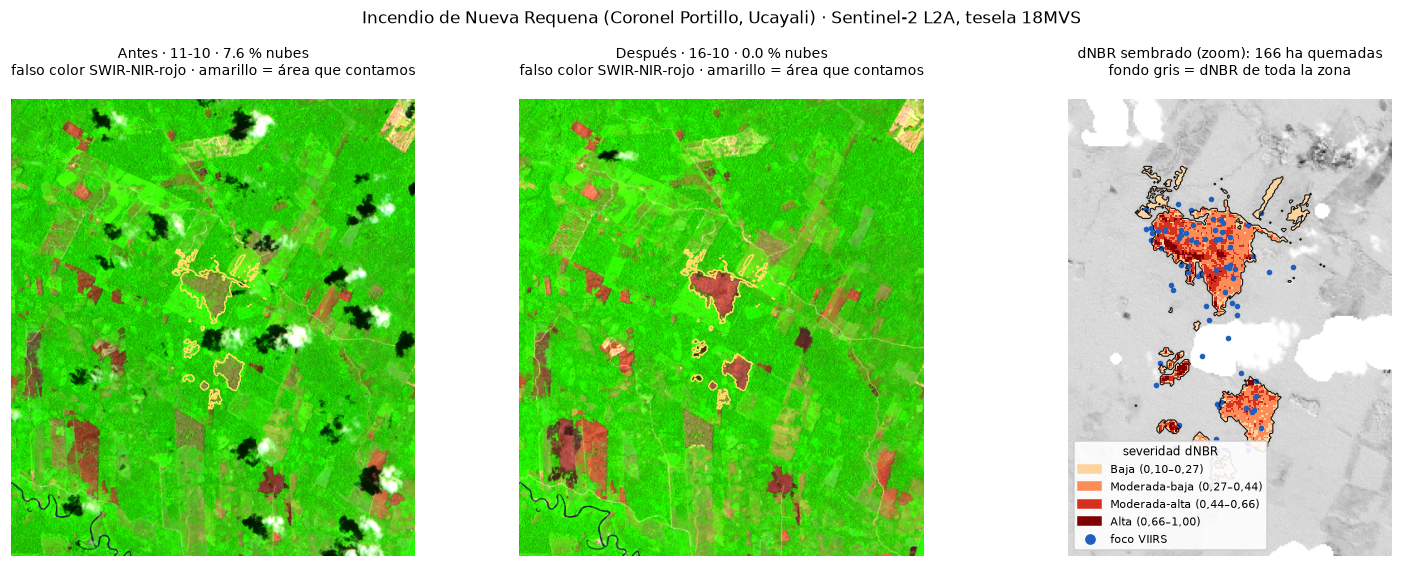

In [19]:
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

def estirar(rgb):
    lo, hi = np.nanpercentile(rgb, [2, 98])
    return np.clip((rgb - lo) / (hi - lo), 0, 1)

extension = plotting_extent(dnbr, transform)
COLORES = ["#fdd49e", "#fc8d59", "#d7301f", "#7f0000"]
paleta = ListedColormap(COLORES)
clases = BoundaryNorm([0.10, 0.27, 0.44, 0.66, 2], paleta.N)
focos_fuego = fuego.to_crs(crs)

# Zoom del tercer panel: la cicatriz más 800 m de margen
filas, columnas = np.where(quemado)
x_min, y_max = transform * (columnas.min(), filas.min())
x_max, y_min = transform * (columnas.max() + 1, filas.max() + 1)

fig, ejes = plt.subplots(1, 3, figsize=(14, 5.2))
for ax, rgb, titulo in [
    (ejes[0], color_antes, f"Antes · {antes.fecha:%d-%m} · {antes['nubes_zona_%']:.1f} % nubes"),
    (ejes[1], color_despues, f"Después · {despues.fecha:%d-%m} · "
                             f"{despues['nubes_zona_%']:.1f} % nubes"),
]:
    ax.imshow(estirar(rgb), extent=extension)
    ax.contour(quemado.astype(int), levels=[0.5], colors="#ffe066", linewidths=0.9,
               extent=extension, origin="upper")
    ax.set_title(f"{titulo}\nfalso color SWIR-NIR-rojo · amarillo = área que contamos",
                 fontsize=9)

ejes[2].imshow(dnbr, extent=extension, cmap="Greys", vmin=-0.2, vmax=0.6)
ejes[2].imshow(np.where(quemado, dnbr, np.nan), extent=extension, cmap=paleta, norm=clases,
               interpolation="nearest")
ejes[2].contour(quemado.astype(int), levels=[0.5], colors="#111", linewidths=0.7,
                extent=extension, origin="upper")
focos_fuego.plot(ax=ejes[2], color="#1f5fbf", markersize=7)
ejes[2].set_xlim(x_min - 800, x_max + 800)
ejes[2].set_ylim(y_min - 800, y_max + 800)
leyenda = [Patch(color=c, label=f"{nombre} ({lo:.2f}–{min(hi, 1):.2f})".replace(".", ","))
           for c, (lo, hi, nombre) in zip(COLORES, SEVERIDAD)]
leyenda.append(plt.Line2D([], [], marker="o", color="#1f5fbf", linestyle="", label="foco VIIRS"))
ejes[2].legend(handles=leyenda, loc="lower left", fontsize=7.5, title="severidad dNBR",
               title_fontsize=8, framealpha=0.9)
ejes[2].set_title(f"dNBR sembrado (zoom): {quemado.sum() * ha_pixel:,.0f} ha quemadas\n"
                  "fondo gris = dNBR de toda la zona", fontsize=9)
for ax in ejes:
    ax.set_axis_off()
fig.suptitle(f"Incendio de {ELEGIDO.nombre} (Coronel Portillo, Ucayali) · Sentinel-2 L2A, "
             f"tesela {despues.tesela}", fontsize=11)
plt.tight_layout()
fig.savefig(SALIDAS / "dnbr_nueva_requena.png", dpi=130, bbox_inches="tight")
plt.show()

**Raster → tabla, otra vez con `zonal_stats`.** Es la operación central de la clase, usada
dos veces:

1. **¿En qué distritos cayó el área quemada?** Le pasamos a `zonal_stats` un `np.array`
   (la máscara de quemado) junto con su `affine`.
2. **¿Qué se quemó?** Convertimos la máscara en un polígono y lo cruzamos con WorldCover a
   10 m, con `categorical=True` para contar píxeles por clase.

In [20]:
from rasterstats import zonal_stats

from rasterio.merge import merge
from rasterio.transform import array_bounds

cerca = distritos.to_crs(crs)
cerca = cerca[cerca.intersects(box(*array_bounds(*dnbr.shape, transform)))]

por_dist = zonal_stats(cerca, quemado.astype("uint8"), affine=transform,
                       stats=["sum"], nodata=255)
cerca = cerca.assign(ha_quemadas=[(s["sum"] or 0) * ha_pixel for s in por_dist])
display(cerca[["NOMBDIST", "NOMBPROV", "ha_quemadas"]].query("ha_quemadas > 0"))

# Del raster al polígono: cada mancha quemada pasa a ser una geometría
poligonos = [shape(g) for g, v in shapes(quemado.astype("uint8"), mask=quemado,
                                         transform=transform) if v == 1]
cicatriz = gpd.GeoSeries(poligonos, crs=crs).union_all()
cicatriz_wgs = gpd.GeoSeries([cicatriz], crs=crs).to_crs(4326)

# El incendio cae justo en el borde de dos teselas de WorldCover (-75°): las unimos en un
# mosaico, leyendo solo el rectángulo de la cicatriz
teselas_wc = CATALOGO.search(collections=["esa-worldcover"], intersects=zona_wgs,
                             query={"esa_worldcover:product_version": {"eq": "2.0.0"}}).items()
fuentes = [rasterio.open(t.assets["map"].href) for t in teselas_wc]
mosaico, transform_wc = merge(fuentes, bounds=tuple(cicatriz_wgs.total_bounds))
for f in fuentes:
    f.close()
print(f"WorldCover: {len(fuentes)} teselas unidas en un mosaico de {mosaico.shape[2]} x {mosaico.shape[1]} px")

que_se_quemo = zonal_stats(cicatriz_wgs, mosaico[0], affine=transform_wc, nodata=0,
                           categorical=True, category_map=COBERTURA)[0]
que_se_quemo = (pd.Series(que_se_quemo, name="píxeles").sort_values(ascending=False)
                  .to_frame().assign(**{"%": lambda t: t["píxeles"] / t["píxeles"].sum() * 100}))
que_se_quemo

,NOMBDIST,NOMBPROV,ha_quemadas
1366,NUEVA REQUENA,CORONEL PORTILLO,165.5


WorldCover: 2 teselas unidas en un mosaico de 246 x 417 px


,píxeles,%
Bosque,18751,95.6
Pastizal,865,4.4


## 8 · Resumen en números

In [21]:
r1 = ranking.iloc[0]
semana_top5 = semana.groupby("fecha").agg(focos=("focos", "sum"), lluvia=("lluvia_mm", "mean"))
pico_14_16 = semana_top5.loc["2026-10-14":"2026-10-16", "focos"].sum()
despues_17 = semana_top5.loc["2026-10-17":, "focos"].sum()
print("SEMANA 14-21 OCT")
print(f"  focos VIIRS en el Perú: {len(focos):,} · tras limpiar con WorldCover: {len(veg):,}")
print(f"  top 5 distritos: {por_distrito.head(5).huella_ha.sum():,.0f} ha de huella "
      f"({por_distrito.head(5).huella_ha.sum() / por_distrito.huella_ha.sum():.0%} del país)")
print(f"  focos de la tarde en el top 5: 14-16 oct = {pico_14_16:,} · 17-21 oct = {despues_17:,}")
print(f"  lluvia media del top 5 el 17 oct: {semana_top5.loc['2026-10-17', 'lluvia']:.0f} mm")
print("\nPRONÓSTICO 22-28 OCT")
for _, r in ranking.iterrows():
    print(f"  {r.distrito:<15} {r.dias_riesgo} días de riesgo ({r.cuales}) · "
          f"HDW hasta {r.hdw_max_relativo:.1f}x el pico · {r.lluvia_7d_mm:.0f} mm en 7 días · "
          f"empuja hacia el {r.avanzaria_hacia}")
print("\nÁREA QUEMADA (dNBR)")
print(f"  {ELEGIDO.nombre}: {quemado.sum() * ha_pixel:,.0f} ha vs huella VIIRS {huella_viirs:,.0f} ha")
print(f"  severidad moderada o alta: {severidad.hectareas.iloc[1:].sum():,.0f} ha")
print(f"  imágenes {antes.fecha:%d-%m} ({antes['nubes_zona_%']:.1f} % nubes) y "
      f"{despues.fecha:%d-%m} ({despues['nubes_zona_%']:.1f} % nubes)")

SEMANA 14-21 OCT
  focos VIIRS en el Perú: 9,949 · tras limpiar con WorldCover: 9,226
  top 5 distritos: 15,697 ha de huella (17% del país)
  focos de la tarde en el top 5: 14-16 oct = 1,103 · 17-21 oct = 203
  lluvia media del top 5 el 17 oct: 24 mm

PRONÓSTICO 22-28 OCT
  Rio Tambo       2 días de riesgo (sáb 24, dom 25) · HDW hasta 1.7x el pico · 19 mm en 7 días · empuja hacia el oeste
  Raymondi        1 días de riesgo (dom 25) · HDW hasta 2.0x el pico · 72 mm en 7 días · empuja hacia el sureste
  Tahuania        1 días de riesgo (dom 25) · HDW hasta 1.1x el pico · 60 mm en 7 días · empuja hacia el sur
  Masisea         1 días de riesgo (dom 25) · HDW hasta 1.0x el pico · 55 mm en 7 días · empuja hacia el sur
  Nueva Requena   0 días de riesgo (—) · HDW hasta 0.8x el pico · 60 mm en 7 días · empuja hacia el sur

ÁREA QUEMADA (dNBR)
  Nueva Requena: 166 ha vs huella VIIRS 412 ha
  severidad moderada o alta: 115 ha
  imágenes 11-10 (7.6 % nubes) y 16-10 (0.0 % nubes)


## 9 · Hallazgos

**1 · La lluvia del 17 de octubre cortó el pico de la semana.** Del 14 al 16 de octubre hubo
6 986 focos en el Perú, frente a 2 963 en los cinco días siguientes. En los 5 distritos más
afectados, los focos de la tarde pasaron de 1 103 (14 al 16) a 203 (17 al 21). El 17 cayeron
en promedio 24 mm de lluvia sobre esos distritos, y el HDW no volvió a los niveles del pico.

**2 · El domingo 25 de octubre es el día de riesgo, y Río Tambo es el incendio que más puede
crecer.**
- Cuatro de los cinco distritos tienen el 25 como día de riesgo: 0 mm de lluvia y un HDW
  igual o mayor al de sus días pico. En Raymondi el HDW llega a **2,0 veces** su pico.
- **Río Tambo** (Satipo, Junín) es el único con **dos** días de riesgo (sábado 24 y domingo
  25, con un HDW de 1,7 y 1,6 veces su pico). También es el que menos lluvia espera en la
  semana: 19 mm, frente a 55–72 mm en los distritos de Ucayali. Ahí el viento empujaría el
  fuego hacia el **oeste**.
- **Nueva Requena**, el distrito con más huella, **no tiene ningún día de riesgo**: su HDW
  pronosticado no pasa de 0,8 veces el de su pico. *El distrito más afectado no es el que
  más puede crecer.*

**3 · La huella VIIRS infla el área 2,5 veces.** El incendio principal de Nueva Requena
quemó **166 ha** según el dNBR de Sentinel-2 (11 de octubre → 16 de octubre, con 7,6 % y 0 %
de nubes en la zona). Su huella VIIRS era de 412 ha. El 69 % del área (115 ha) tiene
severidad moderada o alta. Según WorldCover 2021, el 96 % de lo quemado era **bosque**.

## 10 · Limitaciones

- **Un foco de calor no es un incendio.** Limpiamos el desierto, las fuentes fijas y los
  reflejos en el agua con WorldCover 2021, que tiene cinco años y se leyó a ~80 m. A la
  inversa, **no todo incendio deja foco**: las nubes, el humo y los fuegos chicos o bajo el
  dosel se escapan. En la imagen del 16 de octubre se ven otras cicatrices nuevas que no
  contamos: o son de otros incendios, o ardieron sin que VIIRS las viera.
- **Las nubes esconden el fuego.** Los días de lluvia son días nublados, así que parte de la
  caída de focos del 17 puede ser que el satélite no pudo mirar. En la selva, además, las
  nubes deciden qué incendio se puede medir con Sentinel-2.
- **Open-Meteo es un modelo, no una estación.** Da el clima de una celda de ~10 km en el
  incendio principal de cada distrito, no en el frente del fuego. El HDW es la versión de
  superficie: sirve para comparar días, no para usar los umbrales publicados.
- **La calibración es corta.** Son 8 días y 5 distritos: es una regla razonable para ordenar
  los días, no un modelo estadístico. «Puede crecer» no es «va a crecer»: en la selva casi
  todos los fuegos los prende la gente (quemas agrícolas, desbosque). El clima abre la
  ventana; alguien tiene que prender el fósforo.
- **El dNBR depende de las decisiones**, como muestra la tabla de métodos. Usamos 115 o 166 ha
  según el umbral sea 0,27 o 0,10. La imagen «después» es de la mañana del último día con
  focos, así que lo que ardió esa tarde no está contado.
- **Los datos tienen fecha de corte.** Los focos van del 14 de octubre (00:14) al 21 de
  octubre (14:19, hora de Lima). El pronóstico se bajó el 21 de octubre en la noche.